# [EURON 11기 Research] 11주차 복습과제 — MAE
**Masked Autoencoders Are Scalable Vision Learners** (He et al., CVPR 2022)

이번 복습과제는 세 파트로 구성되어 있습니다.

| 파트 | 내용 | 비고 |
|---|---|---|
| Part 1 | 개념 확인 (단답·서술) | 마크다운 셀에 답 작성 |
| Part 2 | MAE 핵심 로직 직접 구현 (patchify · random masking · masked MSE) | `____` 빈칸 채우기, CPU로 실행 가능 |
| Part 3 | 사전학습된 MAE로 재구성 실험 (Hugging Face `ViTMAEForPreTraining`) | 4주차 ViT 실습(교재 10장)과 같은 FashionMNIST 파이프라인 사용 |
| (선택) Part 4 | 토의 질문 | 자유 서술 |

**제출 방법**
- 이 노트북의 **사본**을 만들어 빈칸을 채우고 모든 셀을 실행한 뒤 `.ipynb`로 제출해 주세요.
- 파일명 & Pull Request 제목: `Week11복습과제_김이화` / 라벨: `복습과제` / branch: `Week_11`
- 코드, 실행 결과, 주석이 모두 포함되도록 해 주세요.

> 런타임: Part 2는 CPU로 충분합니다. Part 3는 GPU(런타임 → 런타임 유형 변경 → T4)를 권장하지만 CPU로도 실행됩니다.

---
## Part 1. 개념 확인

아래 질문에 1~3문장으로 답해 주세요. (발표 자료 #01--#04 참고)

**Q1.** 논문은 NLP와 비교해 비전에서 masked autoencoding이 늦게 발전한 이유를 세 가지 관점으로 설명합니다. 세 관점을 쓰고, 그중 **information density** 관점이 MAE의 어떤 설계로 이어졌는지 설명하세요.

> 답: 세 관점은 (1) **architecture**: CNN은 regular grid 위에서 동작해 mask token·positional embedding 같은 indicator를 넣기 어려웠음(ViT 등장으로 해소), (2) **information density**: 언어는 사람이 만든 의미 밀도가 높은 신호인 반면 이미지는 spatial redundancy가 커서 일부 patch가 빠져도 주변 patch로부터 고수준 이해 없이 복원 가능함, (3) **decoder의 역할**: 언어에서는 decoder가 의미 수준이 높은 단어를 예측해 MLP로 충분하지만, 비전에서는 의미 수준이 낮은 pixel을 복원하므로 decoder 설계가 latent 표현의 의미 수준을 좌우함. 이 중 information density 관점은 **75%라는 매우 높은 masking ratio**로 이어졌음. redundancy를 크게 제거해 단순 보간으로는 풀 수 없는 어려운 self-supervisory task를 만들고, 모델이 전체적인(holistic) 이해를 하도록 유도함.

**Q2.** MAE의 encoder는 mask token을 입력받지 않습니다. 이 설계가 가져오는 이점 두 가지를 쓰세요. (Table 1c 참고: linear probing 73.5 vs 59.6, FLOPs 1× vs 3.3×)

> 답: (1) **성능 향상**: encoder가 실제 visible patch만 보므로, fine-tuning·추론 시에는 등장하지 않는 mask token으로 인한 사전학습-배포 간 불일치(gap)가 사라짐. 그 결과 linear probing 정확도가 59.6 → 73.5로 크게 오름. (2) **계산 효율**: encoder가 전체 patch의 25%만 처리하므로 FLOPs가 3.3배 줄고 학습 시간과 메모리도 크게 감소함. 덕분에 큰 encoder로 쉽게 확장(scaling) 가능함.

**Q3.** MAE는 loss를 왜 **masked patch에서만** 계산할까요? 모든 patch에서 계산하면 어떻게 되었는지(논문 각주)도 함께 쓰세요.

> 답: MAE의 pretext task는 보이지 않는 부분을 추론해 복원하는 것이므로, 입력으로 이미 주어진 visible patch를 그대로 복사하는 쉬운 문제에 학습 신호를 낭비하지 않도록 masked patch에서만 loss를 계산함(BERT와 같은 방식). 논문 각주에 따르면 모든 pixel에서 loss를 계산하면 정확도가 약간(약 0.5%) 떨어짐.

**Q4.** BERT의 masking ratio는 15%인데 MAE는 75%가 최적입니다. 이 차이가 생기는 이유를 설명하세요.

> 답: 언어는 단어 하나하나의 의미 밀도가 높아 15%만 가려도 문맥 추론이 필요한 충분히 어려운 task가 됨. 반면 이미지는 인접 patch 간 redundancy가 커서 낮은 비율로 가리면 주변 patch를 보간하는 것만으로 복원 가능해 저수준 정보만 학습하게 됨. 따라서 75%처럼 높은 비율로 가려야 redundancy가 제거되고 물체·장면 수준의 고수준 표현을 학습함. 동시에 encoder 계산량도 줄어드는 이점이 있음.

**Q5.** MoCo v3는 linear probing이 MAE보다 높지만(77.6 vs 73.5), Transformer block을 하나 이상 fine-tuning하면 항상 MAE보다 낮습니다(Fig. 9). 이 결과가 표현 평가 방식에 대해 시사하는 점은 무엇일까요?

> 답: linear probing은 고정된 feature의 **선형 분리 가능성**만 측정하므로, 비선형적으로 강력하고 전이 가능한 표현을 제대로 평가하지 못함. MAE의 feature는 선형 분리성은 낮지만 block 하나만 fine-tuning해도 MoCo v3를 앞서는데, 이는 linear probing 성능과 실제 전이 학습 성능이 상관이 약함을 보여줌. 따라서 표현 평가 시 linear probing 하나에 의존하지 말고 partial fine-tuning이나 full fine-tuning을 함께 봐야 함.

---
## Part 2. MAE 핵심 로직 직접 구현

공식 코드(`facebookresearch/mae`의 `models_mae.py`)를 바탕으로, MAE에서 가장 중요한 세 함수를 직접 구현합니다.

1. `patchify` : 이미지 `(N, 3, H, W)` → patch 시퀀스 `(N, L, p*p*3)`
2. `random_masking` : noise를 argsort해서 patch를 섞고 앞의 `(1 - mask_ratio)`만 남기기
3. `masked_mse_loss` : **masked patch에서만** MSE 평균

`____` 부분을 채운 뒤 아래 확인용 셀이 모두 통과하는지 확인하세요.

In [1]:
import torch
torch.manual_seed(0)

N, C, H, W, p = 2, 3, 224, 224, 16
imgs = torch.randn(N, C, H, W)
print('patch 개수 L =', (H // p) * (W // p))

patch 개수 L = 196


### 2-1. patchify
`(N, 3, H, W)` → `(N, h, p, w, p, 3)` 순서로 재배열한 뒤 `(N, h*w, p*p*3)`로 펴 줍니다.

In [2]:
def patchify(imgs, p=16):
    N, C, H, W = imgs.shape
    h, w = H // p, W // p
    x = imgs.reshape(N, C, h, p, w, p)
    x = torch.einsum('nchpwq->nhwpqc', x)      # 채널을 맨 뒤로
    x = x.reshape(N, h * w, p * p * C)          # (N, L, p*p*3)
    return x

patches = patchify(imgs, p)
print(patches.shape)   # 기대값: torch.Size([2, 196, 768])
assert patches.shape == (2, 196, 768)
# 첫 번째 patch는 이미지 왼쪽 위 16x16 영역과 같아야 합니다
assert torch.allclose(patches[0, 0], imgs[0, :, :16, :16].permute(1, 2, 0).reshape(-1))
print('patchify 통과!')

torch.Size([2, 196, 768])
patchify 통과!


### 2-2. random_masking
- `len_keep = int(L * (1 - mask_ratio))`
- patch마다 `noise ~ U(0, 1)` → `argsort`하면 sample별 random permutation(`ids_shuffle`)
- `ids_restore = argsort(ids_shuffle)` : 원래 순서로 되돌리는 index
- `mask` : **0 = keep, 1 = remove**, 원래 patch 순서 기준

In [3]:
def random_masking(x, mask_ratio):
    N, L, D = x.shape
    len_keep = int(L * (1 - mask_ratio))

    noise = torch.rand(N, L, device=x.device)          # noise in [0, 1]
    ids_shuffle = torch.argsort(noise, dim=1)          # small is keep, large is remove
    ids_restore = torch.argsort(ids_shuffle, dim=1)

    ids_keep = ids_shuffle[:, :len_keep]
    x_masked = torch.gather(x, dim=1, index=ids_keep.unsqueeze(-1).repeat(1, 1, D))

    mask = torch.ones([N, L], device=x.device)
    mask[:, :len_keep] = 0
    mask = torch.gather(mask, dim=1, index=ids_restore)   # unshuffle
    return x_masked, mask, ids_restore

x_masked, mask, ids_restore = random_masking(patches, mask_ratio=0.75)
print('visible patch:', x_masked.shape)            # 기대값: torch.Size([2, 49, 768])
print('masked 개수 :', mask.sum(dim=1))            # 기대값: tensor([147., 147.])
assert x_masked.shape == (2, 49, 768)
assert torch.all(mask.sum(dim=1) == 147)
# 남은 patch(x_masked)는 mask == 0 인 위치의 patch와 정확히 같아야 합니다
for n in range(N):
    kept = patches[n][mask[n] == 0]
    assert torch.allclose(torch.sort(kept.sum(-1)).values, torch.sort(x_masked[n].sum(-1)).values)
print('random_masking 통과!')

visible patch: torch.Size([2, 49, 768])
masked 개수 : tensor([147., 147.])
random_masking 통과!


### 2-3. unshuffle 확인
decoder에서는 encoder 출력 뒤에 mask token을 붙이고 `ids_restore`로 원래 순서로 되돌립니다.
아래에서는 mask token 대신 **0 벡터**를 붙여, 되돌린 결과가 "visible 위치는 원래 patch, masked 위치는 0"이 되는지 확인합니다.

In [4]:
N, L, D = patches.shape
mask_tokens = torch.zeros(N, L - x_masked.shape[1], D)
x_ = torch.cat([x_masked, mask_tokens], dim=1)
x_ = torch.gather(x_, dim=1, index=ids_restore.unsqueeze(-1).repeat(1, 1, D))

expected = patches * (1 - mask).unsqueeze(-1)
assert torch.allclose(x_, expected)
print('unshuffle 통과! visible patch가 원래 위치로 돌아왔습니다.')

unshuffle 통과! visible patch가 원래 위치로 돌아왔습니다.


### 2-4. masked MSE loss
1. patch별로 pixel 차이의 제곱 평균 → `(N, L)`
2. `mask`(1 = remove)를 곱해 **가려진 patch에서만** 평균

`norm_pix=True`이면 patch마다 평균·분산으로 정규화한 target을 사용합니다(논문 Table 1d의 *pixel (w/ norm)*).

In [5]:
def masked_mse_loss(imgs, pred, mask, p=16, norm_pix=False):
    target = patchify(imgs, p)
    if norm_pix:
        mean = target.mean(dim=-1, keepdim=True)
        var = target.var(dim=-1, keepdim=True)
        target = (target - mean) / (var + 1.e-6) ** .5

    loss = (pred - target) ** 2
    loss = loss.mean(dim=-1)                 # [N, L], patch별 평균
    loss = (loss * mask).sum() / mask.sum()  # masked patch에서만 평균
    return loss

# 확인: visible patch만 틀리고 masked patch는 정답인 예측 -> loss는 0이어야 합니다
pred = patchify(imgs, p).clone()
pred[mask == 0] += 5.0
print('loss =', masked_mse_loss(imgs, pred, mask).item())   # 기대값: 0.0
assert masked_mse_loss(imgs, pred, mask).item() == 0.0
print('masked_mse_loss 통과!')

loss = 0.0
masked_mse_loss 통과!


**Q6.** 위 확인 셀에서 visible patch를 크게 틀리게 예측했는데도 loss가 0이 된 이유를 쓰고, 이것이 Part 3의 재구성 이미지(`reconstruction`)에서 어떻게 드러날지 예상해 보세요.

> 답: patch별 loss에 mask(visible = 0, masked = 1)를 곱하므로 visible patch의 오차는 0이 되어 합계에서 빠지고, masked patch만으로 평균을 내기 때문임. 이번 예측은 masked patch가 정답이었으므로 loss가 0이 됨. 즉 모델은 visible patch를 정확히 복원하도록 학습되지 않음. 따라서 Part 3의 `reconstruction`에서 visible 위치는 원본과 다르거나 덜 정교하게(뭉개지거나 블록처럼) 나올 것으로 예상되며, 이 때문에 visible patch를 원본으로 덮어쓴 `recon + visible`을 함께 확인함.

---
## Part 3. 사전학습된 MAE로 재구성 실험

Hugging Face의 `ViTMAEForPreTraining`(`facebook/vit-mae-base`)을 불러와 FashionMNIST 이미지를 재구성해 봅니다.
데이터 전처리는 **4주차 ViT 실습(교재 10장 p.609~624)**과 같은 방식(1채널 → 3채널 복제, `AutoImageProcessor`의 mean/std로 정규화)을 사용합니다.

> 참고: 이 모델은 ImageNet으로 사전학습되었고 FashionMNIST는 본 적이 없습니다.

In [6]:
!pip -q install transformers

import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from transformers import AutoImageProcessor, ViTMAEForPreTraining

device = 'cuda' if torch.cuda.is_available() else 'cpu'
image_processor = AutoImageProcessor.from_pretrained('facebook/vit-mae-base')
model = ViTMAEForPreTraining.from_pretrained('facebook/vit-mae-base').to(device).eval()

print('mask_ratio   :', model.config.mask_ratio)
print('norm_pix_loss:', model.config.norm_pix_loss)
print('encoder      :', model.config.num_hidden_layers, 'blocks,', model.config.hidden_size, '-d')
print('decoder      :', model.config.decoder_num_hidden_layers, 'blocks,', model.config.decoder_hidden_size, '-d')

preprocessor_config.json:   0%|          | 0.00/217 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/676 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  448MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/334 [00:00<?, ?it/s]

mask_ratio   : 0.75
norm_pix_loss: False
encoder      : 12 blocks, 768 -d
decoder      : 8 blocks, 512 -d


**Q7.** 위 출력에서 encoder와 decoder의 깊이·너비를 비교하고, 논문이 decoder를 이렇게 설계한 이유를 쓰세요.

> 답: encoder는 12 blocks, 768-d(ViT-Base)이고 decoder는 8 blocks, 512-d로, decoder가 encoder보다 얕고 좁은 **비대칭(asymmetric) 경량 구조**임. decoder는 사전학습 중 pixel 복원에만 쓰이고 downstream task에는 encoder만 사용하므로 encoder와 독립적으로 가볍게 설계 가능함. 또한 decoder는 mask token까지 포함한 전체 L개 token을 처리하므로, 가볍게 만들어야 사전학습 계산량이 크게 줄어듦(논문 기본 decoder는 token당 계산량이 encoder의 10% 미만). 논문 실험상 fine-tuning 성능은 decoder 깊이에 거의 둔감했고, linear probing은 decoder가 어느 정도 깊어야 encoder 마지막 층이 복원 전용 특성 대신 추상적 표현을 학습해 성능이 좋아졌음.

In [7]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize(size=(image_processor.size['height'], image_processor.size['width'])),
    transforms.Lambda(lambda x: torch.cat([x, x, x], 0)),        # 1채널 -> 3채널
    transforms.Normalize(mean=image_processor.image_mean, std=image_processor.image_std),
])
test_dataset = datasets.FashionMNIST(root='./datasets', download=True, train=False, transform=transform)
classes = test_dataset.classes

pixel_values = torch.stack([test_dataset[i][0] for i in range(4)]).to(device)
print(pixel_values.shape)   # 기대값: torch.Size([4, 3, 224, 224])

100%|██████████| 26.4M/26.4M [00:01<00:00, 20.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 381kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.19MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.3MB/s]

torch.Size([4, 3, 224, 224])


loss (mask 75%) = 0.0599


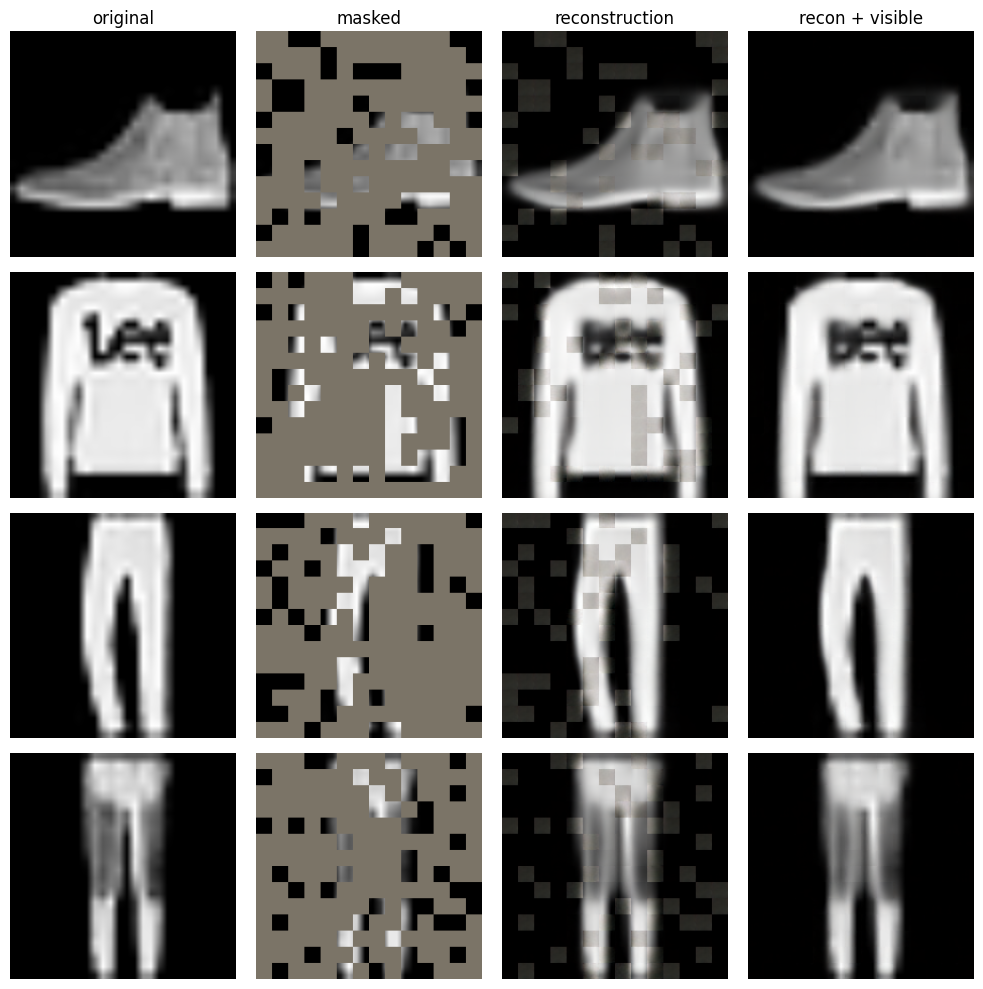

In [8]:
mean = torch.tensor(image_processor.image_mean).view(3, 1, 1)
std = torch.tensor(image_processor.image_std).view(3, 1, 1)

def to_img(t):
    # (3, H, W) 정규화 텐서 -> (H, W, 3) 이미지
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0)

@torch.no_grad()
def reconstruct(pixel_values, mask_ratio=0.75, seed=0):
    model.config.mask_ratio = mask_ratio
    torch.manual_seed(seed)
    out = model(pixel_values)
    pred = model.unpatchify(out.logits)                        # (N, 3, H, W)
    p = model.config.patch_size
    mask = out.mask.unsqueeze(-1).repeat(1, 1, p * p * 3)      # (N, L, p*p*3)
    mask = model.unpatchify(mask)                              # 1 = remove, 0 = keep
    masked = pixel_values * (1 - mask)
    paste = pixel_values * (1 - mask) + pred * mask          # visible patch는 원본으로 덮어쓰기
    return out.loss.item(), masked, pred, paste

loss, masked, pred, paste = reconstruct(pixel_values, mask_ratio=0.75)
print(f'loss (mask 75%) = {loss:.4f}')

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i in range(4):
    for j, (img, title) in enumerate([(pixel_values[i], 'original'), (masked[i], 'masked'),
                                      (pred[i], 'reconstruction'), (paste[i], 'recon + visible')]):
        axes[i, j].imshow(to_img(img)); axes[i, j].axis('off')
        if i == 0: axes[i, j].set_title(title)
plt.tight_layout(); plt.show()

### 3-2. masking ratio를 바꿔 보기
같은 이미지에 대해 masking ratio를 0.25 → 0.95로 바꿔 가며 loss와 재구성 결과를 비교합니다.

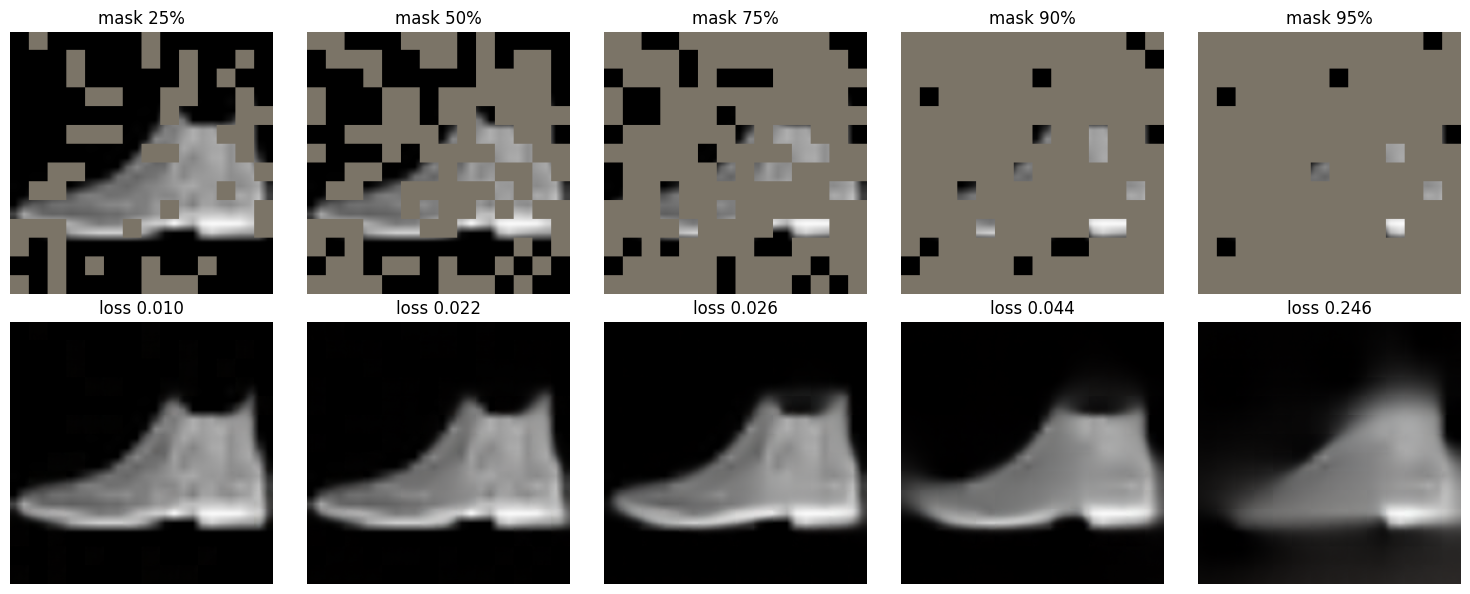

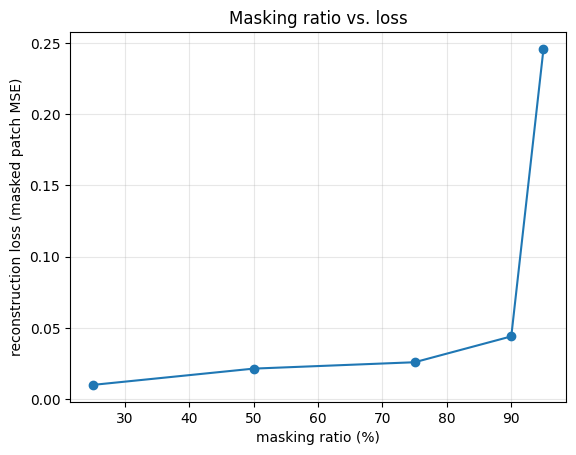

In [9]:
ratios = [0.25, 0.5, 0.75, 0.9, 0.95]
losses = []
fig, axes = plt.subplots(2, len(ratios), figsize=(3 * len(ratios), 6))
for k, r in enumerate(ratios):
    loss, masked, pred, paste = reconstruct(pixel_values[:1], mask_ratio=r)
    losses.append(loss)
    axes[0, k].imshow(to_img(masked[0])); axes[0, k].set_title(f'mask {int(r*100)}%'); axes[0, k].axis('off')
    axes[1, k].imshow(to_img(paste[0])); axes[1, k].set_title(f'loss {loss:.3f}'); axes[1, k].axis('off')
plt.tight_layout(); plt.show()

plt.plot([int(r * 100) for r in ratios], losses, marker='o')
plt.xlabel('masking ratio (%)'); plt.ylabel('reconstruction loss (masked patch MSE)')
plt.title('Masking ratio vs. loss'); plt.grid(alpha=.3); plt.show()
model.config.mask_ratio = 0.75   # 원래 값으로 복구

**Q8.** masking ratio가 커질수록 loss와 재구성 결과는 어떻게 변했나요? 이 결과와 논문 Fig. 5(75%가 최적)를 연결해, "복원이 잘 되는 것"과 "좋은 표현을 배우는 것"이 같은지 다른지 의견을 쓰세요.

> 답: masking ratio가 커질수록 masked patch 복원 loss가 대체로 증가하고, 90%·95%에서는 재구성 결과가 흐릿해지며 옷의 형태·세부 무늬가 뭉개짐. (※ 실행 결과의 실제 loss 수치를 확인해 필요 시 보완) 복원 자체는 낮은 비율(25%)에서 가장 잘 되지만, 논문 Fig. 5에서 fine-tuning·linear probing 성능은 75% 부근에서 가장 높았음. 낮은 비율에서는 주변 patch 보간만으로 쉽게 복원되어 저수준 정보만 배우고, 너무 높으면 단서가 부족함. 따라서 "복원이 잘 되는 것"과 "좋은 표현을 배우는 것"은 다르며, 복원이 어렵지만 풀 수는 있는 수준의 task가 좋은 표현 학습으로 이어진다고 판단함.

**Q9.** `reconstruction` 열에서 visible patch 위치가 오히려 더 거칠게(블록처럼) 보였다면 그 이유는 무엇일까요? (Part 2의 Q6와 연결)

> 답: Q6에서 확인했듯 loss가 masked patch에서만 계산되므로 visible patch 위치의 출력에는 학습 신호가 전혀 없음. 따라서 모델은 visible 위치를 원본처럼 정교하게 출력할 이유가 없어, 해당 위치가 patch 단위로 거칠고 블록처럼 보일 수 있음. 이 위치는 이미 원본을 알고 있으므로 시각화 시 원본으로 덮어쓰는 것(`recon + visible`)이 일반적임.

---
## (선택) Part 4. 토의 질문

1. 최적 masking ratio 75%는 데이터의 redundancy에 따라 달라질까요? 비디오·의료 영상·FashionMNIST처럼 배경이 단순한 이미지라면 어떨까요?
2. MAE의 "visible patch만 encoder에 넣기"는 ViT라서 가능한 설계입니다. CNN에 같은 아이디어를 적용하려면 무엇이 필요할까요?

> 답: 1. 최적 masking ratio는 데이터의 redundancy에 따라 달라질 것으로 봄. 비디오는 시간 축 redundancy까지 더해져 더 높은 비율이 유리함(VideoMAE·MAE-ST는 약 90%를 사용). 의료 영상은 작은 병변처럼 국소적 세부 정보가 중요하므로 너무 높은 비율은 핵심 정보를 지울 수 있어 데이터별 조정이 필요함. FashionMNIST처럼 배경이 단순한 이미지는 상당수 patch가 검은 배경이라 random masking 시 쉬운 patch가 많이 섞임. 따라서 비율을 더 높이거나 전경 위주로 masking하는 방식이 필요할 수 있음.

2. CNN은 regular grid 위에서 sliding window로 동작하므로 visible patch만 골라 입력할 수 없음. 가린 부분을 0으로 채우면 계산량이 줄지 않고, 층이 깊어질수록 receptive field가 넓어지며 mask 경계 정보가 섞임. 따라서 visible 위치에서만 연산하는 **sparse convolution**(SparK, ConvNeXt V2의 FCMAE)처럼 불규칙한 입력을 처리하는 연산과, 계층적 구조에서 해상도마다 mask를 일관되게 맞추는 설계가 필요함.

---
**참고 자료**
- He et al. (2022). *Masked Autoencoders Are Scalable Vision Learners*. CVPR. https://arxiv.org/abs/2111.06377
- 공식 코드: https://github.com/facebookresearch/mae (`models_mae.py`)
- Hugging Face ViTMAE 문서: https://huggingface.co/docs/transformers/model_doc/vit_mae
- 교재: 파이토치 트랜스포머를 활용한 자연어 처리와 컴퓨터비전 심층학습, 10장 ViT 실습 (p.609~624)